# Inteligencia Artificial Avanzada

## Entrega 3 - Experimento 5: Transfer Learning con MobileNetV2

Se utiliza MobileNetV2 con pesos ImageNet como extractor congelado y se entrena un clasificador nuevo para las ocho especies. Las imágenes se procesan completas: Object Detection y el recorte central están desactivados. No se aplica Data Augmentation ni fine-tuning.

`imagen RGB completa -> normalización a [-1, 1] -> MobileNetV2 congelada -> GAP y clasificador -> especie -> catálogo regional -> Nativa/Exótica`

Se compara esta configuración preentrenada con la CNN desde cero del Experimento 2 y con el control 4C. Cambian la arquitectura del extractor y sus pesos iniciales; la comparación no separa por sí sola el efecto del preentrenamiento del cambio de arquitectura.


**Exportacion actual:** `run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2`. Se corrigieron descripciones, catalogo, exportacion y metadatos de sesion sin reentrenar. Las salidas son las aportadas por el grupo. La nueva exportacion conserva las metricas medidas: accuracy de especie 74,875 % y macro-F1 74,481 %.


In [ ]:
#@title 1. Configuracion general

EXPERIMENT_NUMBER = 5
EXPERIMENT_ID = "exp5_transfer_learning_mobilenetv2"
EXPERIMENT_TITLE = "Exp. 5 - Transfer Learning MobileNetV2"
USE_OBJECT_DETECTION = False


SEED = 42 #@param {type:"integer"}
MAX_IMAGES_PER_SPECIES = 400 #@param {type:"integer"}
MIN_IMAGES_RECOMMENDED = 100 #@param {type:"integer"}

IMG_SIZE = 224 #@param {type:"integer"}
BATCH_SIZE = 32 #@param {type:"integer"}
EPOCHS = 200 #@param {type:"integer"}
LEARNING_RATE = 0.001 #@param {type:"number"}

TEST_FRACTION = 0.25
VAL_FRACTION_TOTAL = 0.15
TRAIN_FRACTION_TOTAL = 0.60

USE_GOOGLE_DRIVE = True #@param {type:"boolean"}
FORCE_REDOWNLOAD = False #@param {type:"boolean"}

# La condicion nativa/exotica se determina por catalogo regional.
RESTRICT_OBSERVATIONS_TO_BA = False #@param {type:"boolean"}
print("Experimento:", EXPERIMENT_NUMBER, "-", EXPERIMENT_TITLE)
print(f"Split objetivo: train={TRAIN_FRACTION_TOTAL:.0%}, val={VAL_FRACTION_TOTAL:.0%}, test={TEST_FRACTION:.0%}")


Experimento: 5 - Exp. 5 - Transfer Learning MobileNetV2
Split objetivo: train=60%, val=15%, test=25%


In [ ]:
#@title 2. Librerias y reproducibilidad

import os
import re
import io
import json
import time
import shutil
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import requests
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



def slugify_species(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(name).strip()).strip("_")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

def dataset_partition_sha256(frame):
    import hashlib
    columns = ["observation_id", "photo_id", "scientific_name", "condition_ba", "split"]
    data = frame[columns].astype(str).copy()
    data["scientific_name"] = data["scientific_name"].map(
        lambda value: re.sub(r"[^a-z0-9]+", "_", value.strip().casefold()).strip("_")
    )
    records = sorted(data.values.tolist())
    payload = json.dumps(records, ensure_ascii=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


TensorFlow: 2.20.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/gdrive', force_remount=False)
    BASE_DIR = Path('/content/gdrive/MyDrive/2026_IAA_GrupoC')
else:
    BASE_DIR = Path('/content/2026_IAA_GrupoC')



RAW_DIR = BASE_DIR / "dataset_raw"
MANIFEST_PATH = BASE_DIR / "manifest_inaturalist.csv"

ARTIFACTS_ROOT = BASE_DIR / "artifacts_entrega3"
RESULTS_ROOT = ARTIFACTS_ROOT / "runs"
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_NAME = f"run_{RUN_TIMESTAMP}_{EXPERIMENT_ID}"
RUN_DIR = RESULTS_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
ARTIFACTS_DIR = RUN_DIR

WORK_DIR = Path("/content/iaa_work") / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=False)
CROP_SPLIT_DIR = WORK_DIR / "dataset_sin_recorte"

BALANCED_MANIFEST_PATH = RUN_DIR / "manifest_balanceado.csv"
SPLIT_MANIFEST_PATH = RUN_DIR / "manifest_splits.csv"
CROP_MANIFEST_PATH = RUN_DIR / "manifest_splits_object_detection_crop.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)
print("Resultados en Drive:", RUN_DIR)
print("Imagenes temporales en Colab:", WORK_DIR)


Mounted at /content/gdrive
Resultados en Drive: /content/gdrive/MyDrive/2026_IAA_GrupoC/artifacts_entrega3/runs/run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2
Imagenes temporales en Colab: /content/iaa_work/run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2


## 4. Catálogo regional de especies

Se mantienen las ocho especies del prototipo de Entrega 2: cuatro nativas y cuatro exóticas en la Provincia de Buenos Aires. La red predice la especie; la condición regional se obtiene después mediante el catálogo, no mediante una segunda red ni una salida binaria entrenada.


In [ ]:
#@title 4.1 Catálogo de especies del prototipo

SPECIES_CATALOG = pd.DataFrame([

    {
        "scientific_name": "Erythrina crista-galli",
        "common_name": "Ceibo",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Passiflora caerulea",
        "common_name": "Mburucuyá",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Cortaderia selloana",
        "common_name": "Cortadera",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Phytolacca dioica",
        "common_name": "Ombú",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Ligustrum lucidum",
        "common_name": "Ligustro",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Gleditsia triacanthos",
        "common_name": "Acacia negra",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Melia azedarach",
        "common_name": "Paraíso",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Iris pseudacorus",
        "common_name": "Lirio amarillo",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

])

SPECIES_CATALOG["folder_name"] = (
    SPECIES_CATALOG["scientific_name"]
    .apply(slugify_species)
)

display(SPECIES_CATALOG)
print("\nCantidad de especies:", len(SPECIES_CATALOG))
print(SPECIES_CATALOG["condition_ba"].value_counts())


          scientific_name     common_name condition_ba    status_source  \
0  Erythrina crista-galli           Ceibo       Nativa  Flora Argentina   
1     Passiflora caerulea       Mburucuyá       Nativa  Flora Argentina   
2     Cortaderia selloana       Cortadera       Nativa  Flora Argentina   
3       Phytolacca dioica            Ombú       Nativa  Flora Argentina   
4       Ligustrum lucidum        Ligustro      Exótica  Flora Argentina   
5   Gleditsia triacanthos    Acacia negra      Exótica  Flora Argentina   
6         Melia azedarach         Paraíso      Exótica  Flora Argentina   
7        Iris pseudacorus  Lirio amarillo      Exótica  Flora Argentina   

              folder_name  
0  Erythrina_crista_galli  
1     Passiflora_caerulea  
2     Cortaderia_selloana  
3       Phytolacca_dioica  
4       Ligustrum_lucidum  
5   Gleditsia_triacanthos  
6         Melia_azedarach  
7        Iris_pseudacorus  


Cantidad de especies: 8
condition_ba
Nativa     4
Exótica    4
Name: count, dtype: int64


In [ ]:
#@title 4.2 Validacion del catalogo regional

required_fields = [
    "scientific_name",
    "common_name",
    "condition_ba",
    "status_source",
    "folder_name"
]

missing_catalog_data = SPECIES_CATALOG[required_fields].isna().sum()

print("Campos faltantes:")
display(missing_catalog_data.to_frame("faltantes"))

print("\nCondiciones:")
display(
    SPECIES_CATALOG["condition_ba"]
    .value_counts()
    .rename("cantidad")
    .to_frame()
)

assert SPECIES_CATALOG["folder_name"].is_unique, "Los folder_name del catalogo deben ser unicos."


Campos faltantes:


                 faltantes
scientific_name          0
common_name              0
condition_ba             0
status_source            0
folder_name              0


Condiciones:


              cantidad
condition_ba          
Nativa               4
Exótica              4

## 5. Dataset de iNaturalist

La corrida guardada reutiliza el dataset existente de iNaturalist. Si no existe el manifiesto, las funciones permiten construirlo tomando una fotografía por observación con grado de investigación, hasta el límite configurado por especie. `RESTRICT_OBSERVATIONS_TO_BA=False`: las fotografías no están restringidas a Buenos Aires; la condición nativa/exótica sí corresponde a esa provincia.

El manifiesto conserva identificadores de observación y fotografía, especie, condición regional, URL, licencia, atribución, fecha, coordenadas disponibles y ruta local. El código admite `cc0`, `cc-by`, `cc-by-sa`, `cc-by-nc` y `cc-by-nc-sa`, y guarda las descargas como JPEG RGB.


In [ ]:
#@title 5.1 Funciones para consultar iNaturalist y descargar imágenes

INAT_API = "https://api.inaturalist.org/v1"
SESSION = requests.Session()
SESSION.headers.update({
    "User-Agent": "UTN-FRBA-IAA-TP-Plantas/1.0 (academic prototype)"
})

# Licencias de fotografía que admitimos en este prototipo.
ALLOWED_LICENSES = {
    "cc0",
    "cc-by",
    "cc-by-sa",
    "cc-by-nc",
    "cc-by-nc-sa",
}

# Bounding box aproximado de Provincia de Buenos Aires.
BA_BBOX = {
    "swlat": -41.2,
    "swlng": -63.6,
    "nelat": -33.2,
    "nelng": -56.4,
}

def resolve_taxon_id(scientific_name):
    """Busca el taxon_id de una especie en iNaturalist."""
    r = SESSION.get(
        f"{INAT_API}/taxa",
        params={"q": scientific_name, "rank": "species", "per_page": 10},
        timeout=30
    )
    r.raise_for_status()
    results = r.json().get("results", [])

    # Primero intenta coincidencia exacta.
    for taxon in results:
        if taxon.get("name", "").lower() == scientific_name.lower():
            return taxon["id"]

    # Si no existe coincidencia exacta, toma el primer resultado.
    if results:
        warnings.warn(
            f"No hubo coincidencia exacta para {scientific_name}. "
            f"Se utilizará: {results[0].get('name')}"
        )
        return results[0]["id"]

    raise ValueError(f"No se encontró taxón para: {scientific_name}")


def photo_medium_url(photo):
    """
    iNaturalist suele devolver una URL con tamaño 'square'.
    La reemplazamos por 'medium' para obtener una imagen útil sin bajar archivos enormes.
    """
    url = photo.get("url")
    if not url:
        return None
    return url.replace("/square.", "/medium.").replace("square.", "medium.")


def iter_observation_records(scientific_name, taxon_id, condition_ba, max_records):
    """Devuelve registros candidatos, uno por observación."""
    page = 1
    collected = 0
    seen_obs = set()

    while collected < max_records:
        params = {
            "taxon_id": taxon_id,
            "quality_grade": "research",
            "photos": "true",
            "per_page": 200,
            "page": page,
            "order_by": "created_at",
            "order": "desc",
        }

        if RESTRICT_OBSERVATIONS_TO_BA:
            params.update(BA_BBOX)

        r = SESSION.get(f"{INAT_API}/observations", params=params, timeout=45)
        r.raise_for_status()
        payload = r.json()
        results = payload.get("results", [])

        if not results:
            break

        for obs in results:
            obs_id = obs.get("id")
            if obs_id in seen_obs:
                continue
            seen_obs.add(obs_id)

            photos = obs.get("photos") or []
            if not photos:
                continue

            # Se toma una sola foto por observación.
            photo = photos[0]
            license_code = (photo.get("license_code") or "").lower()

            if license_code not in ALLOWED_LICENSES:
                continue

            url = photo_medium_url(photo)
            if not url:
                continue

            geojson = obs.get("geojson") or {}
            coords = geojson.get("coordinates") or [None, None]
            lng = coords[0] if len(coords) > 0 else None
            lat = coords[1] if len(coords) > 1 else None

            yield {
                "observation_id": obs_id,
                "scientific_name": scientific_name,
                "condition_ba": condition_ba,
                "observation_url": f"https://www.inaturalist.org/observations/{obs_id}",
                "photo_id": photo.get("id"),
                "photo_url": url,
                "license_code": license_code,
                "attribution": photo.get("attribution"),
                "observed_on": obs.get("observed_on"),
                "latitude": lat,
                "longitude": lng,
            }

            collected += 1
            if collected >= max_records:
                break

        page += 1
        if page > 20:
            break

        time.sleep(0.15)


def download_image(url, out_path):
    """Descarga, valida y normaliza una imagen a JPEG RGB."""
    r = SESSION.get(url, timeout=45)
    r.raise_for_status()

    img = Image.open(io.BytesIO(r.content)).convert("RGB")
    if min(img.size) < 80:
        raise ValueError(f"Imagen demasiado pequeña: {img.size}")

    out_path.parent.mkdir(parents=True, exist_ok=True)
    img.save(out_path, format="JPEG", quality=92)


def build_dataset_from_inaturalist():
    if FORCE_REDOWNLOAD and RAW_DIR.exists():
        print("FORCE_REDOWNLOAD=True -> borrando dataset_raw existente...")
        shutil.rmtree(RAW_DIR)
        RAW_DIR.mkdir(parents=True, exist_ok=True)

    if MANIFEST_PATH.exists() and not FORCE_REDOWNLOAD:
        print("Se encontró manifest existente. Se reutiliza:")
        print(MANIFEST_PATH)
        df = pd.read_csv(MANIFEST_PATH)
        return df

    records_downloaded = []

    for _, row in SPECIES_CATALOG.iterrows():
        species = row["scientific_name"]
        condition = row["condition_ba"]
        folder = RAW_DIR / row["folder_name"]

        print("\n" + "=" * 80)
        print("Especie:", species, "|", condition)

        taxon_id = resolve_taxon_id(species)
        print("taxon_id:", taxon_id)

        ok = 0
        errors = 0

        # Pedimos algo más que el objetivo porque algunas descargas pueden fallar.
        candidate_limit = int(MAX_IMAGES_PER_SPECIES * 1.5)

        for rec in iter_observation_records(
            scientific_name=species,
            taxon_id=taxon_id,
            condition_ba=condition,
            max_records=candidate_limit
        ):
            if ok >= MAX_IMAGES_PER_SPECIES:
                break

            out_path = folder / f"obs_{rec['observation_id']}_photo_{rec['photo_id']}.jpg"

            try:
                if not out_path.exists():
                    download_image(rec["photo_url"], out_path)

                rec["local_path"] = str(out_path)
                rec["folder_name"] = row["folder_name"]
                rec["common_name"] = row["common_name"]
                records_downloaded.append(rec)

                ok += 1

                if ok % 25 == 0:
                    print(f"  {ok}/{MAX_IMAGES_PER_SPECIES} imágenes válidas")

            except Exception as e:
                errors += 1
                if errors <= 3:
                    print("  Error descartado:", type(e).__name__, str(e)[:120])

        print(f"Final: {ok} imágenes válidas | {errors} errores de descarga/lectura")

    df = pd.DataFrame(records_downloaded)
    df.to_csv(MANIFEST_PATH, index=False)

    print("\nManifest guardado en:", MANIFEST_PATH)
    return df


In [ ]:
#@title 5.2 Descargar / reutilizar dataset

manifest = build_dataset_from_inaturalist()

print("\nTotal imágenes:", len(manifest))
display(
    manifest.groupby(["scientific_name", "condition_ba"])
            .size()
            .rename("cantidad")
            .reset_index()
)


Se encontró manifest existente. Se reutiliza:
/content/gdrive/MyDrive/2026_IAA_GrupoC/manifest_inaturalist.csv

Total imágenes: 3200


          scientific_name condition_ba  cantidad
0     Cortaderia selloana       Nativa       400
1  Erythrina crista-galli       Nativa       400
2   Gleditsia triacanthos      Exótica       400
3        Iris pseudacorus      Exótica       400
4       Ligustrum lucidum      Exótica       400
5         Melia azedarach      Exótica       400
6     Passiflora caerulea       Nativa       400
7       Phytolacca dioica       Nativa       400

Archivos faltantes: 0


                        cantidad
scientific_name                 
Cortaderia selloana          400
Erythrina crista-galli       400
Gleditsia triacanthos        400
Iris pseudacorus             400
Ligustrum lucidum            400
Melia azedarach              400
Passiflora caerulea          400
Phytolacca dioica            400

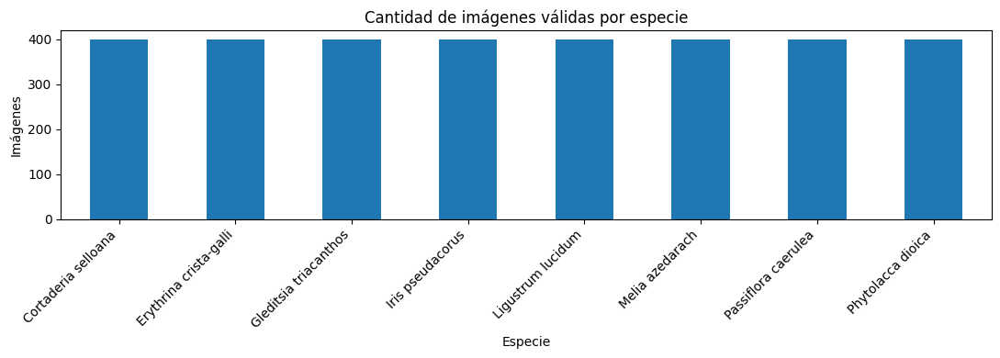

/tmp/ipykernel_1463/1113349836.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(n_per_class, len(x)), random_state=SEED))


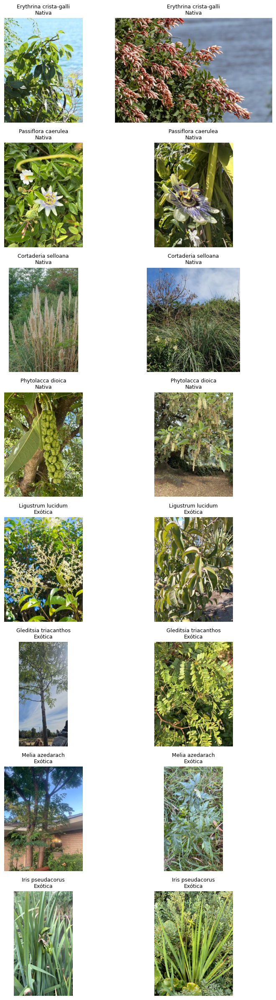

In [ ]:
#@title 6. Auditar dataset: archivos, cantidades y ejemplos

# Verifica que los archivos realmente existan.
manifest["file_exists"] = manifest["local_path"].apply(lambda p: Path(p).exists())
missing = (~manifest["file_exists"]).sum()
print("Archivos faltantes:", missing)

manifest = manifest[manifest["file_exists"]].copy()

counts = manifest["scientific_name"].value_counts().sort_index()
display(counts.rename("cantidad").to_frame())

plt.figure(figsize=(11, 4))
counts.plot(kind="bar")
plt.title("Cantidad de imágenes válidas por especie")
plt.ylabel("Imágenes")
plt.xlabel("Especie")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Muestra 2 ejemplos por especie.
n_per_class = 2
sample_df = (
    manifest.groupby("scientific_name", group_keys=False)
            .apply(lambda x: x.sample(min(n_per_class, len(x)), random_state=SEED))
            .reset_index(drop=True)
)

fig, axes = plt.subplots(len(SPECIES_CATALOG), n_per_class, figsize=(8, 3 * len(SPECIES_CATALOG)))
if len(SPECIES_CATALOG) == 1:
    axes = np.array([axes])

for ax in np.array(axes).reshape(-1):
    ax.axis("off")

for i, (_, row) in enumerate(sample_df.iterrows()):
    species_idx = list(SPECIES_CATALOG["scientific_name"]).index(row["scientific_name"])
    pos_in_species = sum(sample_df.iloc[:i]["scientific_name"] == row["scientific_name"])
    ax = axes[species_idx, pos_in_species]
    img = Image.open(row["local_path"])
    ax.imshow(img)
    ax.set_title(f"{row['scientific_name']}\n{row['condition_ba']}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

if counts.min() < MIN_IMAGES_RECOMMENDED:
    warnings.warn(
        f"La clase con menos imágenes tiene {counts.min()}. "
        "Conviene revisar la lista de especies o aumentar la descarga."
    )


## 7. Balanceo, partición y auditoría

La corrida contiene 3.200 imágenes: 400 por especie. El muestreo balanceado y la partición estratificada utilizan la semilla 42:

- Entrenamiento: 1.920 imágenes (60 %; 240 por especie).
- Validación: 480 imágenes (15 %; 60 por especie).
- Prueba: 800 imágenes (25 %; 100 por especie).

El notebook recalcula las particiones a partir del manifiesto; no importa automáticamente las particiones de una corrida anterior. Reproducirlas requiere conservar el dataset, su orden y la configuración. Se audita que una observación no aparezca en más de una partición; este control no demuestra ausencia de fotografías visualmente duplicadas entre observaciones diferentes.

El conjunto de prueba no participa en `fit` ni en los callbacks. Sus resultados se inspeccionaron durante la comparación exploratoria de experimentos; no deben presentarse como una evaluación externa que nunca se consultó durante el desarrollo.


In [ ]:
#@title 7.1 Balancear clases

counts = manifest.groupby("scientific_name").size()
n_balance = int(min(counts.min(), MAX_IMAGES_PER_SPECIES))

print("Cantidad balanceada por especie:", n_balance)

balanced = (
    manifest.groupby("scientific_name", group_keys=False)
            .apply(lambda x: x.sample(n=n_balance, random_state=SEED))
            .reset_index(drop=True)
)

balanced.to_csv(BALANCED_MANIFEST_PATH, index=False)

display(
    balanced.groupby(["scientific_name", "condition_ba"])
            .size()
            .rename("cantidad")
            .reset_index()
)

print("Total balanceado:", len(balanced))


Cantidad balanceada por especie: 400


/tmp/ipykernel_1463/3750194505.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=n_balance, random_state=SEED))


          scientific_name condition_ba  cantidad
0     Cortaderia selloana       Nativa       400
1  Erythrina crista-galli       Nativa       400
2   Gleditsia triacanthos      Exótica       400
3        Iris pseudacorus      Exótica       400
4       Ligustrum lucidum      Exótica       400
5         Melia azedarach      Exótica       400
6     Passiflora caerulea       Nativa       400
7       Phytolacca dioica       Nativa       400

Total balanceado: 3200


In [ ]:
#@title 7.2 Separar 60% entrenamiento / 15% validación / 25% prueba

train_val_df, test_df = train_test_split(
    balanced,
    test_size=TEST_FRACTION,
    random_state=SEED,
    stratify=balanced["scientific_name"]
)

# El 15% del total equivale al 20% del bloque restante (75%).
val_fraction_of_remaining = VAL_FRACTION_TOTAL / (1.0 - TEST_FRACTION)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=val_fraction_of_remaining,
    random_state=SEED,
    stratify=train_val_df["scientific_name"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

split_manifest = pd.concat([train_df, val_df, test_df], ignore_index=True)
split_manifest.to_csv(SPLIT_MANIFEST_PATH, index=False)

print("Cantidades:")
print(split_manifest["split"].value_counts())
print("\nPorcentajes reales:")
print(split_manifest["split"].value_counts(normalize=True).sort_index())

print("\nDistribución por especie y split:")
display(pd.crosstab(split_manifest["scientific_name"], split_manifest["split"]))


Cantidades:
split
train    1920
test      800
val       480
Name: count, dtype: int64

Porcentajes reales:
split
test     0.25
train    0.60
val      0.15
Name: proportion, dtype: float64

Distribución por especie y split:


split                   test  train  val
scientific_name                         
Cortaderia selloana      100    240   60
Erythrina crista-galli   100    240   60
Gleditsia triacanthos    100    240   60
Iris pseudacorus         100    240   60
Ligustrum lucidum        100    240   60
Melia azedarach          100    240   60
Passiflora caerulea      100    240   60
Phytolacca dioica        100    240   60

In [ ]:
#@title 7.3 Auditoría cuantitativa del dataset

# ============================================================
# Distribución por especie y split
# ============================================================

audit_species = pd.crosstab(
    split_manifest["scientific_name"],
    split_manifest["split"]
)

# Orden deseado
for col in ["train", "val", "test"]:
    if col not in audit_species.columns:
        audit_species[col] = 0

audit_species = audit_species[
    ["train", "val", "test"]
]

audit_species["total"] = audit_species.sum(axis=1)

print("Distribución por especie:")
display(audit_species)


# ============================================================
# Distribución por condición regional
# ============================================================

audit_condition = pd.crosstab(
    split_manifest["condition_ba"],
    split_manifest["split"]
)

for col in ["train", "val", "test"]:
    if col not in audit_condition.columns:
        audit_condition[col] = 0

audit_condition = audit_condition[
    ["train", "val", "test"]
]

audit_condition["total"] = audit_condition.sum(axis=1)

print("\nDistribución por condición:")
display(audit_condition)


# ============================================================
# Resumen general
# ============================================================

dataset_summary = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba", "Total"],
    "Cantidad": [
        len(train_df),
        len(val_df),
        len(test_df),
        len(split_manifest)
    ]
})

dataset_summary["Porcentaje"] = (
    dataset_summary["Cantidad"] /
    len(split_manifest) * 100
)

# El total debe mostrarse como 100%
dataset_summary.loc[
    dataset_summary["Conjunto"] == "Total",
    "Porcentaje"
] = 100

print("\nResumen del dataset:")
display(dataset_summary)


# ============================================================
# Validaciones automáticas
# ============================================================

print("\nControles:")

print(
    "Cantidad de especies:",
    split_manifest["scientific_name"].nunique()
)

print(
    "Cantidad de condiciones:",
    split_manifest["condition_ba"].nunique()
)

print(
    "Duplicados observation_id:",
    split_manifest["observation_id"].duplicated().sum()
)

print(
    "Duplicados local_path:",
    split_manifest["local_path"].duplicated().sum()
)


# Verifica que una observación no haya quedado en más de un split
obs_split_count = (
    split_manifest
    .groupby("observation_id")["split"]
    .nunique()
)

leakage_count = (obs_split_count > 1).sum()

print(
    "Observaciones presentes en más de un split:",
    leakage_count
)


if leakage_count == 0:
    print("✅ No se detectó leakage por observation_id.")
else:
    print("⚠️ Revisar separación del dataset.")


# ============================================================
# Guardar tablas
# ============================================================

audit_species.to_csv(
    ARTIFACTS_DIR / "auditoria_especies_split.csv"
)

audit_condition.to_csv(
    ARTIFACTS_DIR / "auditoria_condicion_split.csv"
)

dataset_summary.to_csv(
    ARTIFACTS_DIR / "auditoria_resumen_dataset.csv",
    index=False
)

if leakage_count or split_manifest["observation_id"].duplicated().any():
    raise ValueError("Observaciones duplicadas o compartidas entre particiones.")


Distribución por especie:


split                   train  val  test  total
scientific_name                                
Cortaderia selloana       240   60   100    400
Erythrina crista-galli    240   60   100    400
Gleditsia triacanthos     240   60   100    400
Iris pseudacorus          240   60   100    400
Ligustrum lucidum         240   60   100    400
Melia azedarach           240   60   100    400
Passiflora caerulea       240   60   100    400
Phytolacca dioica         240   60   100    400


Distribución por condición:


split         train  val  test  total
condition_ba                         
Exótica         960  240   400   1600
Nativa          960  240   400   1600


Resumen del dataset:


        Conjunto  Cantidad  Porcentaje
0  Entrenamiento      1920        60.0
1     Validación       480        15.0
2         Prueba       800        25.0
3          Total      3200       100.0


Controles:
Cantidad de especies: 8
Cantidad de condiciones: 2
Duplicados observation_id: 0
Duplicados local_path: 0
Observaciones presentes en más de un split: 0
✅ No se detectó leakage por observation_id.


## 8. Preparación de imágenes completas

En esta corrida `USE_OBJECT_DETECTION=False` y `FALLBACK_CENTER_CROP=False`. No se carga ni se ejecuta el detector: las 3.200 imágenes conservan el encuadre completo. Se retiraron las funciones y dependencias del detector no utilizadas.

El circuito convierte a RGB y vuelve a guardar cada imagen como JPEG con calidad 92 en el almacenamiento temporal de Colab. La ausencia de recorte no implica igualdad exacta de píxeles con el archivo de origen. Las imágenes se redimensionan después a 224 x 224 al cargarlas para el modelo.

Los nombres `crop_path`, `cropped_manifest`, los archivos con `object_detection` y la etiqueta `full_image_fallback` son heredados del formato de exportación. Aquí describen imágenes completas y una tasa de detección del 0 %. No se generan figuras comparativas de recortes. Se conservan los manifiestos necesarios para el procesamiento y la trazabilidad.


In [ ]:
#@title 8.1 Preparacion sin detector
assert not USE_OBJECT_DETECTION
print("Imagenes completas, sin detector ni recorte central.")


Object Detection activado: False


In [ ]:
#@title 8.2 Preparar imagen completa RGB

def crop_image_with_detector(source_path, output_path):
    # Conserva la recodificacion JPEG de las corridas originales sin detector.
    with Image.open(source_path) as source_image:
        img = source_image.convert("RGB")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    img.save(output_path, format="JPEG", quality=92)
    return {
        "crop_path": str(output_path),
        "crop_method": "full_image_fallback",
        "detected": False,
        "detection_score": None,
        "detection_class_id": None,
        "detection_class_name": None,
        "crop_x1": 0, "crop_y1": 0,
        "crop_x2": img.width, "crop_y2": img.height,
        "source_width": img.width, "source_height": img.height,
    }


In [ ]:
#@title 8.3 Generar imagenes completas de esta corrida

def crop_split_dataset(split_manifest):
    if CROP_SPLIT_DIR.exists():
        shutil.rmtree(CROP_SPLIT_DIR)

    records = []
    for row in tqdm(split_manifest.itertuples(index=False), total=len(split_manifest)):
        source_path = Path(row.local_path)
        dst = CROP_SPLIT_DIR / row.split / row.folder_name / source_path.name
        base_record = row._asdict()

        try:
            crop_info = crop_image_with_detector(source_path, dst)
            base_record.update(crop_info)
            base_record["crop_error"] = None
            records.append(base_record)
        except Exception as e:
            base_record["crop_path"] = None
            base_record["crop_method"] = "error"
            base_record["detected"] = False
            base_record["detection_score"] = None
            base_record["detection_class_id"] = None
            base_record["detection_class_name"] = None
            base_record["crop_error"] = f"{type(e).__name__}: {str(e)[:160]}"
            records.append(base_record)

    cropped_manifest = pd.DataFrame(records)
    if cropped_manifest["crop_path"].isna().any():
        raise RuntimeError("Fallo la preparacion; no se permite descartar muestras.")
    cropped_manifest.to_csv(CROP_MANIFEST_PATH, index=False)
    print("Imagenes completas preparadas en:", CROP_SPLIT_DIR)
    return cropped_manifest


cropped_manifest = crop_split_dataset(split_manifest)

print("\nResumen de metodos de recorte:")
display(cropped_manifest["crop_method"].value_counts().rename("cantidad").to_frame())

crop_detection_rate = float(cropped_manifest["detected"].mean()) if len(cropped_manifest) else 0.0
print(f"Tasa de deteccion usada para recorte: {crop_detection_rate:.2%}")

cropped_manifest.to_csv(ARTIFACTS_DIR / "manifest_splits_object_detection_crop.csv", index=False)


  0%|          | 0/3200 [00:00<?, ?it/s]

Dataset recortado generado en: /content/iaa_work/run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2/dataset_sin_recorte

Resumen de metodos de recorte:


                     cantidad
crop_method                  
full_image_fallback      3200

Tasa de deteccion usada para recorte: 0.00%


## 9. Carga de imágenes para clasificación

Se cargan las imágenes completas preparadas en la etapa anterior, respetando las particiones. TensorFlow las redimensiona a 224 x 224 en RGB. Las etiquetas se infieren de los nombres de carpeta; validación y prueba se cargan sin barajar. La normalización de píxeles se realiza dentro del modelo.


In [ ]:
#@title 9.1 Crear datasets TensorFlow desde imagenes completas

train_crop_df = cropped_manifest[cropped_manifest["split"] == "train"].copy()
val_crop_df = cropped_manifest[cropped_manifest["split"] == "val"].copy()
test_crop_df = cropped_manifest[cropped_manifest["split"] == "test"].copy()

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "train",
    labels="inferred",
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "val",
    labels="inferred",
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "test",
    labels="inferred",
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("\nClases detectadas:")
for i, c in enumerate(CLASS_NAMES):
    print(i, "->", c)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds_raw.cache().prefetch(AUTOTUNE)
test_ds = test_ds_raw.cache().prefetch(AUTOTUNE)

TEST_FILE_PATHS = list(test_ds_raw.file_paths)
crop_lookup = cropped_manifest.set_index("crop_path").to_dict(orient="index")


Found 1920 files belonging to 8 classes.
Found 480 files belonging to 8 classes.
Found 800 files belonging to 8 classes.

Clases detectadas:
0 -> Cortaderia_selloana
1 -> Erythrina_crista-galli
2 -> Gleditsia_triacanthos
3 -> Iris_pseudacorus
4 -> Ligustrum_lucidum
5 -> Melia_azedarach
6 -> Passiflora_caerulea
7 -> Phytolacca_dioica


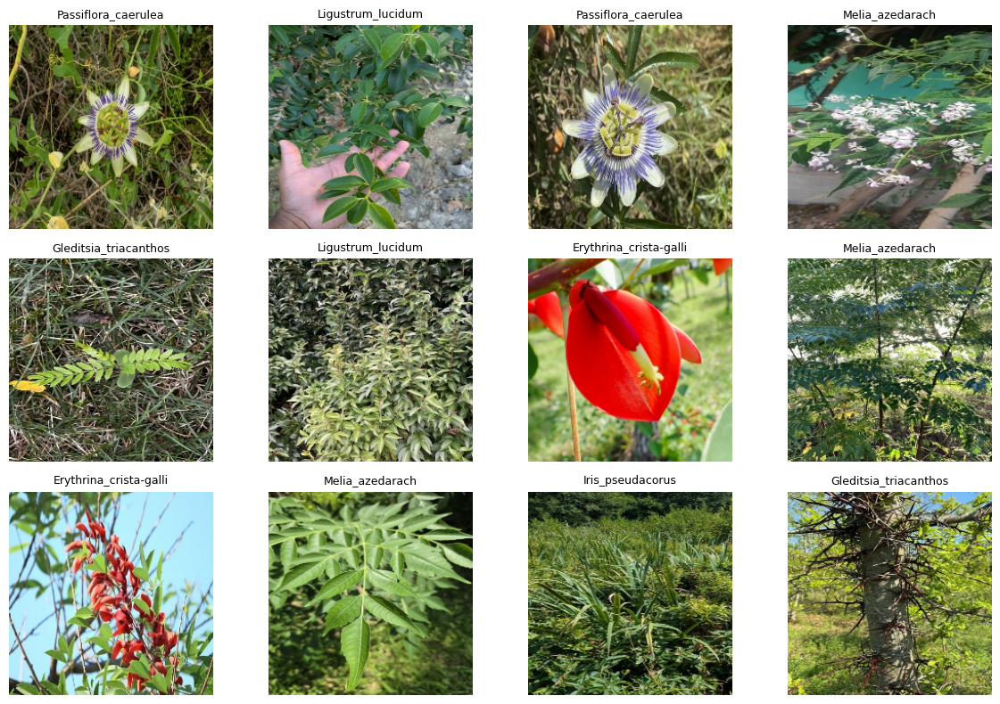

In [ ]:
#@title 9.2 Visualizar un batch de entrenamiento

images_batch, labels_batch = next(iter(train_ds))

plt.figure(figsize=(12, 8))
for i in range(min(12, len(images_batch))):
    ax = plt.subplot(3, 4, i + 1)
    plt.imshow(images_batch[i].numpy().astype("uint8"))
    class_idx = int(np.argmax(labels_batch[i].numpy()))
    plt.title(CLASS_NAMES[class_idx], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


## 10. Transfer Learning con MobileNetV2 congelada

MobileNetV2 se carga con pesos ImageNet, sin su clasificador original (`include_top=False`). La base permanece congelada y se invoca con `training=False`. La entrada RGB de 224 x 224 se transforma de [0, 255] a [-1, 1] mediante una capa del propio modelo.

Sobre la base se agregan GAP, Dense de 128 unidades, Dropout 0,30 y softmax de ocho clases. Se entrenan 165.000 parámetros del clasificador; 2.257.984 permanecen congelados, con un total de 2.422.984. No se realiza fine-tuning.

Adam comienza en 0,001. La tasa se reduce a la mitad tras cuatro épocas sin mejora suficiente de `val_loss`, hasta un mínimo de 0,00001. Early Stopping usa paciencia 12 y recupera los mejores pesos. El máximo es 200 épocas; el entrenamiento terminó en la 17 y recuperó la 5. Por eso las métricas de prueba corresponden a la época 5, no a la última época ejecutada ni a la de mayor accuracy de validación.


In [ ]:
#@title 10.1 Transfer Learning con MobileNetV2 congelada

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3), name="input_img"
)

# Convierte pixeles de [0, 255] a [-1, 1].
x = layers.Rescaling(
    scale=1.0 / 127.5, offset=-1, name="preprocessing"
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dense(128, activation="relu", name="dense_1")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES, activation="softmax", name="output"
)(x)

model = keras.Model(inputs, outputs, name="Exp5_MobileNetV2")

optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)
model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

assert len(base_model.trainable_weights) == 0
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Exp5_MobileNetV2"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_img (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocessing (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤

 Total params: 2,422,984 (9.24 MB)


 Trainable params: 165,000 (644.53 KB)


 Non-trainable params: 2,257,984 (8.61 MB)


In [ ]:
#@title 10.2 Entrenar modelo

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df["phase"] = "training"


Epoch 1/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 28s 120ms/step - accuracy: 0.5453 - loss: 1.3273 - val_accuracy: 0.6917 - val_loss: 0.9436 - learning_rate: 0.0010
Epoch 2/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7109 - loss: 0.8240 - val_accuracy: 0.6938 - val_loss: 0.8543 - learning_rate: 0.0010
Epoch 3/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7719 - loss: 0.6491 - val_accuracy: 0.6917 - val_loss: 0.8604 - learning_rate: 0.0010
Epoch 4/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8016 - loss: 0.5731 - val_accuracy: 0.7250 - val_loss: 0.7782 - learning_rate: 0.0010
Epoch 5/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8458 - loss: 0.4604 - val_accuracy: 0.7188 - val_loss: 0.7770 - learning_rate: 0.0010
Epoch 6/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8719 - loss: 0.3875 - val_accuracy: 0.7417 - val_loss: 0.8164 - learning_rate: 0.0010
Epoch 7/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9010 - loss: 0.3096 

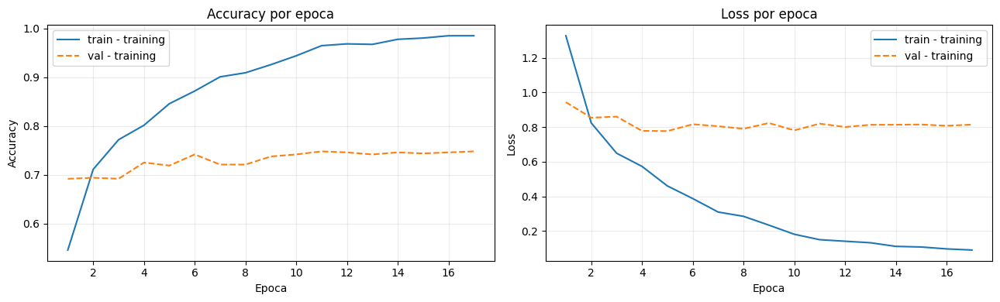

In [ ]:
#@title 10.3 Curvas de entrenamiento y validacion

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for phase_name, phase_df in history_df.groupby("phase", sort=False):
    ax[0].plot(phase_df["epoch"], phase_df["accuracy"], label=f"train - {phase_name}")
    ax[0].plot(phase_df["epoch"], phase_df["val_accuracy"], linestyle="--", label=f"val - {phase_name}")
    ax[1].plot(phase_df["epoch"], phase_df["loss"], label=f"train - {phase_name}")
    ax[1].plot(phase_df["epoch"], phase_df["val_loss"], linestyle="--", label=f"val - {phase_name}")

ax[0].set_title("Accuracy por epoca")
ax[0].set_xlabel("Epoca")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(alpha=0.25)

ax[1].set_title("Loss por epoca")
ax[1].set_xlabel("Epoca")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "curvas_entrenamiento.png", dpi=160, bbox_inches="tight")
history_df.to_csv(ARTIFACTS_DIR / "history_entrenamiento.csv", index=False)


## 11. Evaluación del prototipo

La evaluación se realiza después de recuperar los pesos de la época con menor pérdida de validación.

- **Especie:** clasificación de ocho clases; accuracy, macro-F1 y matriz de confusión.
- **Condición regional:** cada especie predicha se transforma en Nativa o Exótica mediante el catálogo de Buenos Aires; se calculan métricas y una matriz independientes para este resultado derivado.

La columna `confidence` es el máximo de la salida softmax. No representa una probabilidad de acierto calibrada. La normalización de nombres en el mapeo del catálogo contempla variantes con guiones y guiones bajos, incluido el ceibo.


In [ ]:
#@title 11.1 Evaluacion global en prueba

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.7487 - loss: 0.7612

Test loss: 0.7612
Test accuracy: 0.7487


In [ ]:
#@title 11.2 Predicciones y metricas por especie

y_true_onehot = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true = np.argmax(y_true_onehot, axis=1)

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_conf = np.max(y_prob, axis=1)

species_report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

species_report_df = pd.DataFrame(species_report).T
display(species_report_df)

species_macro_f1 = f1_score(y_true, y_pred, average="macro")
species_accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy especie: {species_accuracy:.4f}")
print(f"Macro-F1 especie: {species_macro_f1:.4f}")

species_report_df.to_csv(ARTIFACTS_DIR / "classification_report_especies.csv")


25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step


                        precision   recall  f1-score    support
Cortaderia_selloana      0.774194  0.96000  0.857143  100.00000
Erythrina_crista-galli   0.738739  0.82000  0.777251  100.00000
Gleditsia_triacanthos    0.660194  0.68000  0.669951  100.00000
Iris_pseudacorus         0.964706  0.82000  0.886486  100.00000
Ligustrum_lucidum        0.750000  0.66000  0.702128  100.00000
Melia_azedarach          0.731343  0.49000  0.586826  100.00000
Passiflora_caerulea      0.738739  0.82000  0.777251  100.00000
Phytolacca_dioica        0.666667  0.74000  0.701422  100.00000
accuracy                 0.748750  0.74875  0.748750    0.74875
macro avg                0.753073  0.74875  0.744807  800.00000
weighted avg             0.753073  0.74875  0.744807  800.00000

Accuracy especie: 0.7488
Macro-F1 especie: 0.7448


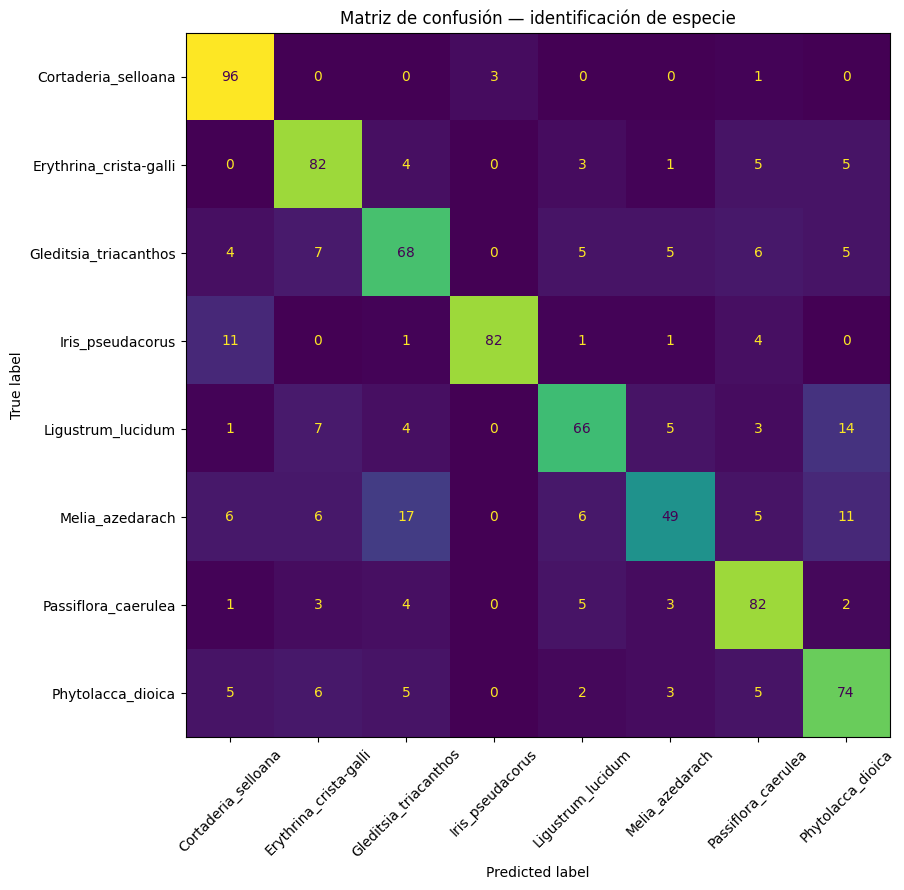

In [ ]:
#@title 11.3 Matriz de confusion por especie

cm_species = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_species,
    display_labels=CLASS_NAMES
)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Matriz de confusión — identificación de especie")
plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "matriz_confusion_especies.png", dpi=170, bbox_inches="tight")


In [ ]:
#@title 11.4 Evaluar clasificacion derivada Nativa / Exotica

import re
import unicodedata

def normalize_species_name(value):
    text = unicodedata.normalize("NFKD", str(value).strip().casefold())
    text = "".join(c for c in text if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", text).strip("_")

catalog = SPECIES_CATALOG.copy()
catalog["_species_key"] = catalog["scientific_name"].map(normalize_species_name)
if catalog["_species_key"].duplicated().any():
    raise ValueError("Especies duplicadas al normalizar el catalogo.")
catalog_by_key = catalog.set_index("_species_key")
class_to_condition = {}
for class_name in CLASS_NAMES:
    key = normalize_species_name(class_name)
    if key not in catalog_by_key.index:
        raise KeyError(f"Clase sin correspondencia regional: {class_name!r}")
    condition = catalog_by_key.loc[key, "condition_ba"]
    if condition not in ["Nativa", "Exótica"]:
        raise ValueError(f"Condicion regional invalida: {class_name!r}")
    class_to_condition[class_name] = condition

true_species_names = [CLASS_NAMES[i] for i in y_true]
pred_species_names = [CLASS_NAMES[i] for i in y_pred]

y_true_condition = np.array([class_to_condition[s] for s in true_species_names])
y_pred_condition = np.array([class_to_condition[s] for s in pred_species_names])

condition_labels = ["Nativa", "Exótica"]

condition_report = classification_report(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels,
    output_dict=True,
    zero_division=0
)

condition_report_df = pd.DataFrame(condition_report).T
display(condition_report_df)

condition_accuracy = accuracy_score(y_true_condition, y_pred_condition)
condition_macro_f1 = f1_score(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels,
    average="macro"
)

print(f"Accuracy condición: {condition_accuracy:.4f}")
print(f"Macro-F1 condición: {condition_macro_f1:.4f}")

condition_report_df.to_csv(ARTIFACTS_DIR / "classification_report_condicion.csv")


              precision   recall  f1-score    support
Nativa         0.803063  0.91750  0.856476  400.00000
Exótica        0.903790  0.77500  0.834455  400.00000
accuracy       0.846250  0.84625  0.846250    0.84625
macro avg      0.853427  0.84625  0.845465  800.00000
weighted avg   0.853427  0.84625  0.845465  800.00000

Accuracy condición: 0.8462
Macro-F1 condición: 0.8455


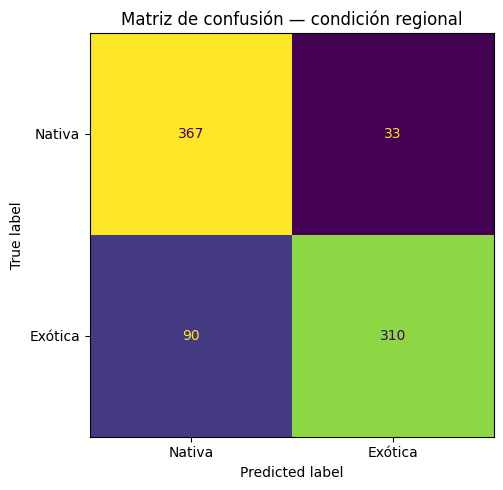

In [ ]:
#@title 11.5 Matriz de confusion Nativa / Exotica

cm_condition = confusion_matrix(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels
)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_condition,
    display_labels=condition_labels
)
disp.plot(ax=ax, values_format="d", colorbar=False)
plt.title("Matriz de confusión — condición regional")
plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "matriz_confusion_condicion.png", dpi=170, bbox_inches="tight")


In [ ]:
#@title 11.6 Tabla de resultados de prueba

source_paths = []
crop_methods = []
detection_scores = []

for crop_path in TEST_FILE_PATHS:
    info = crop_lookup.get(crop_path, {})
    source_paths.append(info.get("local_path", crop_path))
    crop_methods.append(info.get("crop_method", "unknown"))
    detection_scores.append(info.get("detection_score", None))

results_test = pd.DataFrame({
    "crop_path": TEST_FILE_PATHS,
    "source_path": source_paths,
    "crop_method": crop_methods,
    "detection_score": detection_scores,
    "real_species": true_species_names,
    "pred_species": pred_species_names,
    "confidence": y_conf,
    "real_condition": y_true_condition,
    "pred_condition": y_pred_condition,
})

results_test["species_correct"] = results_test["real_species"] == results_test["pred_species"]
results_test["condition_correct"] = results_test["real_condition"] == results_test["pred_condition"]

display(results_test.head(20))

results_test.to_csv(ARTIFACTS_DIR / "resultados_test.csv", index=False)

print("\nErrores de especie:", int((~results_test["species_correct"]).sum()))
print("Errores de condicion:", int((~results_test["condition_correct"]).sum()))


                                            crop_path  \
0   /content/iaa_work/run_20260908_144525_973750_e...   
1   /content/iaa_work/run_20260908_144525_973750_e...   
2   /content/iaa_work/run_20260908_144525_973750_e...   
3   /content/iaa_work/run_20260908_144525_973750_e...   
4   /content/iaa_work/run_20260908_144525_973750_e...   
5   /content/iaa_work/run_20260908_144525_973750_e...   
6   /content/iaa_work/run_20260908_144525_973750_e...   
7   /content/iaa_work/run_20260908_144525_973750_e...   
8   /content/iaa_work/run_20260908_144525_973750_e...   
9   /content/iaa_work/run_20260908_144525_973750_e...   
10  /content/iaa_work/run_20260908_144525_973750_e...   
11  /content/iaa_work/run_20260908_144525_973750_e...   
12  /content/iaa_work/run_20260908_144525_973750_e...   
13  /content/iaa_work/run_20260908_144525_973750_e...   
14  /content/iaa_work/run_20260908_144525_973750_e...   
15  /content/iaa_work/run_20260908_144525_973750_e...   
16  /content/iaa_work/run_20260


Errores de especie: 201
Errores de condicion: 123


## 12. Análisis de errores y ejemplos

Se muestran errores ordenados por el valor máximo de softmax, los pares de especies más confundidos y hasta dos aciertos por especie. Son ejemplos seleccionados para inspección cualitativa, no una muestra aleatoria ni una evaluación adicional. El ranking por softmax permite revisar errores con puntuaciones altas, sin asumir que el modelo esté calibrado.


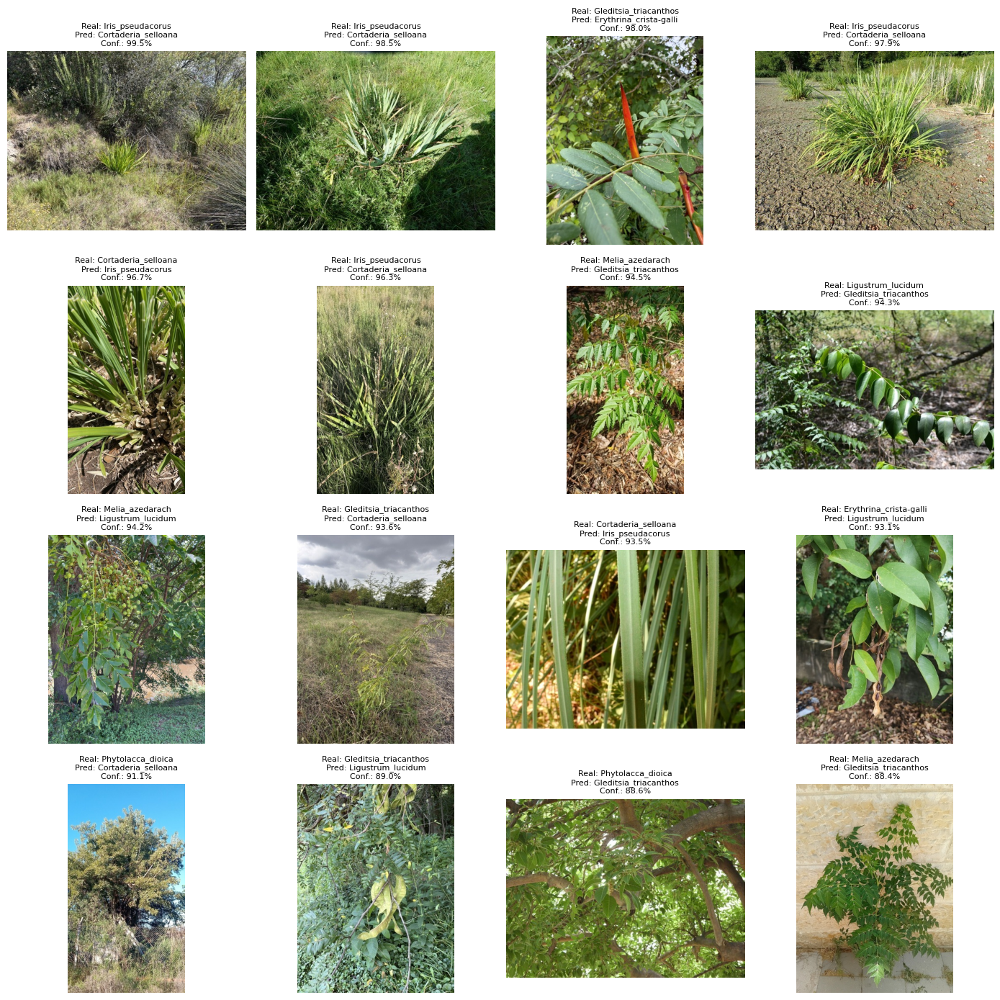

In [ ]:
#@title 12.1 Mostrar errores de clasificacion mas confiados

errors_df = results_test[~results_test["species_correct"]].copy()
errors_df = errors_df.sort_values("confidence", ascending=False)

N_ERRORS_TO_SHOW = min(16, len(errors_df))

if N_ERRORS_TO_SHOW == 0:
    print("No hubo errores de especie en el conjunto de prueba.")
else:
    cols = 4
    rows = int(np.ceil(N_ERRORS_TO_SHOW / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, errors_df.head(N_ERRORS_TO_SHOW).iterrows()):
        img = Image.open(row["crop_path"])
        ax.imshow(img)
        ax.set_title(
            f"Real: {row['real_species']}\n"
            f"Pred: {row['pred_species']}\n"
            f"Conf.: {row['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    fig.savefig(ARTIFACTS_DIR / "errores_representativos.png", dpi=160, bbox_inches="tight")


In [ ]:
#@title 12.2 Resumen de pares de confusion

if len(errors_df):
    confusion_pairs = (
        errors_df.groupby(["real_species", "pred_species"])
                 .size()
                 .rename("cantidad")
                 .reset_index()
                 .sort_values("cantidad", ascending=False)
    )
    display(confusion_pairs.head(20))
else:
    print("Sin pares de confusión para mostrar.")


              real_species            pred_species  cantidad
26         Melia_azedarach   Gleditsia_triacanthos        17
23       Ligustrum_lucidum       Phytolacca_dioica        14
13        Iris_pseudacorus     Cortaderia_selloana        11
29         Melia_azedarach       Phytolacca_dioica        11
8    Gleditsia_triacanthos  Erythrina_crista-galli         7
19       Ligustrum_lucidum  Erythrina_crista-galli         7
11   Gleditsia_triacanthos     Passiflora_caerulea         6
25         Melia_azedarach  Erythrina_crista-galli         6
24         Melia_azedarach     Cortaderia_selloana         6
37       Phytolacca_dioica  Erythrina_crista-galli         6
27         Melia_azedarach       Ligustrum_lucidum         6
38       Phytolacca_dioica   Gleditsia_triacanthos         5
41       Phytolacca_dioica     Passiflora_caerulea         5
33     Passiflora_caerulea       Ligustrum_lucidum         5
21       Ligustrum_lucidum         Melia_azedarach         5
36       Phytolacca_dioi

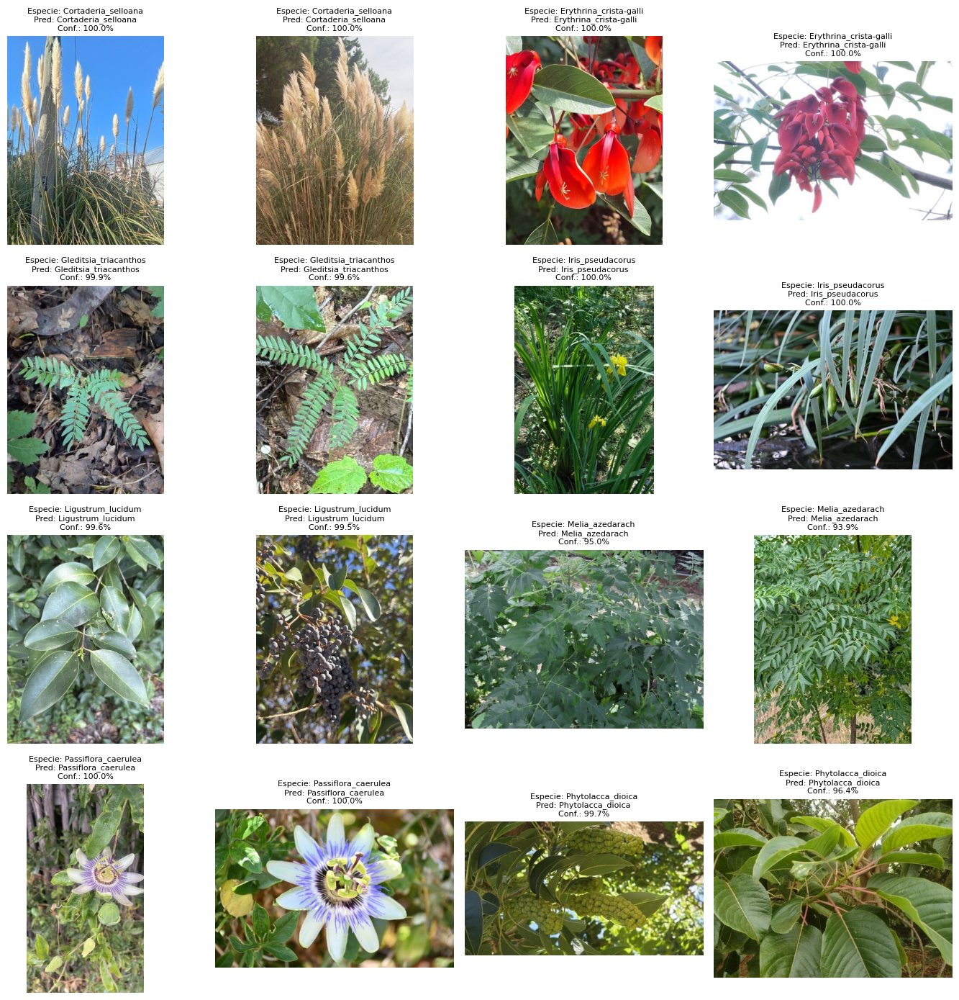

In [ ]:
#@title 12.3 Mostrar 2 aciertos de clasificacion por especie

N_CORRECT_PER_SPECIES = 2
correct_df = results_test[results_test["species_correct"]].copy()
correct_df = correct_df.sort_values("confidence", ascending=False)

selected_examples = []
for species in CLASS_NAMES:
    species_df = correct_df[correct_df["real_species"] == species].head(N_CORRECT_PER_SPECIES)
    selected_examples.append(species_df)

selected_df = pd.concat(selected_examples, ignore_index=True) if selected_examples else pd.DataFrame()

if selected_df.empty:
    print("No hubo aciertos de especie en el conjunto de prueba.")
else:
    cols = 4
    rows = int(np.ceil(len(selected_df) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, selected_df.iterrows()):
        img = Image.open(row["crop_path"])
        ax.imshow(img)
        ax.set_title(
            f"Especie: {row['real_species']}\n"
            f"Pred: {row['pred_species']}\n"
            f"Conf.: {row['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    fig.savefig(ARTIFACTS_DIR / "aciertos_2_por_especie.png", dpi=160, bbox_inches="tight")


## 13. Exportación directa a runs

La celda 3 crea una carpeta fechada en `artifacts_entrega3/runs` y establece `ARTIFACTS_DIR = RUN_DIR`. Las métricas JSON, predicciones e historial CSV, reportes por clase, auditorías, manifiestos, resumen del modelo y figuras PNG se guardan directamente allí, sin una segunda carpeta intermedia de resultados. Volver a ejecutar la celda 3 crea otra carpeta; repetir solo la 13.1 actualiza la corrida actual.

Las copias de imágenes para trabajar quedan en `/content/iaa_work`, fuera de Drive, y se pierden cuando termina la sesión. Los originales permanecen en Drive. Los manifiestos permiten identificar las observaciones y particiones, pero sus rutas temporales no vuelven a existir por descargar únicamente los resultados.

Los nombres heredados con `crop` u `object_detection` se conservan para mantener la correspondencia con los archivos exportados; no indican detección activa en esta corrida. En el resumen, `learning_rate` registra la tasa inicial; su evolución se encuentra en `history_entrenamiento.csv`.

El guardado automático `.keras` permanece comentado en esta celda. Después de la corrida se guardó manualmente `modelo_exp5.keras` para continuar desde esos pesos en el Experimento 6. Ese archivo ya acompaña los resultados locales del 5, y su guardado manual figura en la ultima celda ejecutada de esta copia. Las métricas y los CSV no sustituyen a los pesos del modelo.


In [ ]:
#@title 13.1 Exportar metricas, tablas e imagenes EN GOOGLE DRIVE



best_val_loss_epoch = None
if "val_loss" in history_df.columns and len(history_df):
    best_val_loss_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])

trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
non_trainable_params = int(np.sum([np.prod(v.shape) for v in model.non_trainable_weights]))
total_params = trainable_params + non_trainable_params

metrics_summary = {
    "run_name": RUN_NAME,
    "dataset_partition_sha256": dataset_partition_sha256(cropped_manifest),
    "timestamp": RUN_TIMESTAMP,
    "experiment_number": int(EXPERIMENT_NUMBER),
    "experiment_id": EXPERIMENT_ID,
    "experiment_title": EXPERIMENT_TITLE,
    "seed": int(SEED),
    "img_size": int(IMG_SIZE),
    "batch_size": int(BATCH_SIZE),
    "learning_rate": float(LEARNING_RATE),
    "epochs_configured": int(EPOCHS),
    "epochs_executed": int(len(history_df)),
    "best_val_loss_epoch": best_val_loss_epoch,
    "n_species": int(NUM_CLASSES),
    "n_train": int(len(train_crop_df)),
    "n_val": int(len(val_crop_df)),
    "n_test": int(len(test_crop_df)),
    "object_detection_enabled": bool(USE_OBJECT_DETECTION),
    "object_detection_model_url": None,
    "detection_class_ids": [],
    "detection_score_threshold": None,
    "crop_padding": None,
    "crop_detection_rate": float(crop_detection_rate),
    "crop_methods": cropped_manifest["crop_method"].value_counts().to_dict(),
    "base_classifier": "MobileNetV2",
    "pretrained_weights": "imagenet",
    "base_model_trainable": bool(base_model.trainable),
    "preprocessing": "RGB_0_255_a_menos1_1",
    "transfer_learning": True,
    "fine_tuning": False,
    "trainable_params": trainable_params,
    "non_trainable_params": non_trainable_params,
    "total_params": total_params,
    "test_loss": float(test_loss),
    "test_accuracy_metric": float(test_accuracy),
    "species_accuracy": float(species_accuracy),
    "species_macro_f1": float(species_macro_f1),
    "condition_accuracy": float(condition_accuracy),
    "condition_macro_f1": float(condition_macro_f1),
    "classes": list(CLASS_NAMES),
}

with open(RUN_DIR / f"metricas_entrega3_exp{EXPERIMENT_NUMBER}.json", "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, ensure_ascii=False, indent=2)

history_df.to_csv(RUN_DIR / "history_entrenamiento.csv", index=False)
results_test.to_csv(RUN_DIR / "resultados_test.csv", index=False)
species_report_df.to_csv(RUN_DIR / "classification_report_especies.csv")
condition_report_df.to_csv(RUN_DIR / "classification_report_condicion.csv")
cropped_manifest.to_csv(RUN_DIR / "manifest_splits_object_detection_crop.csv", index=False)

with open(RUN_DIR / "model_summary.txt", "w", encoding="utf-8") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

# El modelo .keras no se exporta por tamano. Descomentar solo si se necesita guardar pesos/modelo.
# MODEL_PATH = RUN_DIR / f"modelo_exp{EXPERIMENT_NUMBER}.keras"
# model.save(str(MODEL_PATH))


README_PATH = RUN_DIR / "README.txt"
with open(README_PATH, "w", encoding="utf-8") as f:
    f.write("IAA - Entrega 3 - Identificacion de especies vegetales\n")
    f.write("=" * 64 + "\n\n")
    f.write(f"Experimento: {EXPERIMENT_NUMBER} - {EXPERIMENT_TITLE}\n")
    f.write(f"Run: {RUN_NAME}\n")
    f.write(f"Resolucion: {IMG_SIZE}x{IMG_SIZE}\n")
    f.write(f"Batch size: {BATCH_SIZE}\n")
    f.write(f"Learning rate: {LEARNING_RATE}\n")
    f.write(f"Epocas ejecutadas: {len(history_df)}\n")
    f.write(f"Mejor epoca por val_loss: {best_val_loss_epoch}\n\n")
    f.write(f"Accuracy especie: {species_accuracy:.4f}\n")
    f.write(f"Macro-F1 especie: {species_macro_f1:.4f}\n")
    f.write(f"Accuracy condicion: {condition_accuracy:.4f}\n")
    f.write(f"Macro-F1 condicion: {condition_macro_f1:.4f}\n")
    f.write(f"Test loss: {test_loss:.4f}\n\n")
    f.write(f"Tasa de deteccion para recorte: {crop_detection_rate:.2%}\n")
    f.write("Nota: el modelo .keras no se exporta automaticamente por tamano.\n")

print("\nArchivos exportados en:")
print(RUN_DIR)
print("\nResumen:")
print(json.dumps(metrics_summary, ensure_ascii=False, indent=2))



Archivos exportados en:
/content/gdrive/MyDrive/2026_IAA_GrupoC/artifacts_entrega3/runs/run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2

Resumen:
{
  "run_name": "run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2",
  "timestamp": "20260908_144525_973750",
  "experiment_number": 5,
  "experiment_id": "exp5_transfer_learning_mobilenetv2",
  "experiment_title": "Exp. 5 - Transfer Learning MobileNetV2",
  "seed": 42,
  "img_size": 224,
  "batch_size": 32,
  "learning_rate": 0.001,
  "epochs_configured": 200,
  "epochs_executed": 17,
  "best_val_loss_epoch": 5,
  "n_species": 8,
  "n_train": 1920,
  "n_val": 480,
  "n_test": 800,
  "object_detection_enabled": false,
  "object_detection_model_url": null,
  "detection_class_ids": [
    64
  ],
  "detection_score_threshold": 0.25,
  "crop_padding": 0.1,
  "crop_detection_rate": 0.0,
  "crop_methods": {
    "full_image_fallback": 3200
  },
  "base_classifier": "MobileNetV2",
  "pretrained_weights": "imagenet",
  "base

In [ ]:
#@title 13.2 Guardado manual opcional del modelo

# Descomentar para guardar los pesos recuperados por Early Stopping.
# assert EXPERIMENT_ID == "exp5_transfer_learning_mobilenetv2"
# assert model.name == "Exp5_MobileNetV2"

# MODEL_PATH = RUN_DIR / "modelo_exp5.keras"
# model.save(str(MODEL_PATH))

# print("Modelo guardado en:", MODEL_PATH)
# print(f"Tamaño: {MODEL_PATH.stat().st_size / 1024**2:.2f} MB")


Modelo guardado en: /content/gdrive/MyDrive/2026_IAA_GrupoC/artifacts_entrega3/runs/run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2/modelo_exp5.keras
Tamaño: 11.07 MB


## 14. Resultados de la corrida guardada

Identificador: `run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2`. Los valores siguientes proceden del resumen JSON mostrado en la celda 13.1 y describen esta ejecución, no futuras repeticiones.

| Métrica | Resultado |
| --- | ---: |
| Accuracy por especie | 74,875 % |
| Macro-F1 por especie | 74,481 % |
| Pérdida en prueba | 0.761206 |
| Accuracy Nativa/Exótica | 84,625 % |
| Macro-F1 Nativa/Exótica | 84,547 % |
| Épocas ejecutadas | 17 |
| Mejor época por pérdida de validación | 5 |

Se obtuvieron 599 aciertos de especie sobre 800 imágenes, frente a 489 del Experimento 2: 110 aciertos adicionales y 13,75 puntos porcentuales más de accuracy. Esta configuración superó al baseline en las métricas globales evaluadas. Las curvas muestran sobreajuste después de las primeras épocas: la accuracy de entrenamiento llega aproximadamente al 98,5 %, mientras la pérdida de validación no mejora respecto de la época 5. Se conserva este modelo como punto de partida del fine-tuning, evaluado posteriormente en los experimentos 6, 7 y 8; ver la sintesis para la comparacion.

Son resultados de una corrida por configuración. Las diferencias observadas no establecen significación estadística ni garantizan el mismo resultado con otras semillas o datos.
